# Student Social Media & Wellbeing: Regression Model

Notebook này khảo sát dữ liệu, xử lý giá trị vận động âm, đánh giá mô hình trên holdout và lưu artifact dùng chung với FastAPI. Điểm `Mental_Health_Score` là điểm khảo sát, không phải chẩn đoán y tế.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "app").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from app.train import (
    DEFAULT_ARTIFACT_PATH,
    DEFAULT_METRICS_PATH,
    DEFAULT_DATA_PATH,
    load_dataset,
    prepare_dataset,
    train_model,
    save_artifacts,
)

pd.set_option("display.max_columns", None)

## 1. Đọc và khảo sát dữ liệu

In [2]:
data = load_dataset(DEFAULT_DATA_PATH)
print(f"Kích thước: {data.shape[0]:,} dòng x {data.shape[1]} cột")
display(data.head())
display(data.dtypes.to_frame("dtype"))
display(data.isna().sum().to_frame("missing"))
display(data.describe(include="all").T)

Kích thước: 5,000 dòng x 13 cột


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


,dtype
Age,int64
Gender,str
Country,str
Academic_Level,str
Most_Used_Platform,str
Purpose_Of_Use,str
Avg_Daily_Usage_Hours,float64
Daily_Unlocks,int64
Study_Hours,float64
Physical_Activity_Hours,float64


,missing
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,5000.0,NaN,NaN,NaN,20.8218,1.73662,18.0,19.0,21.0,22.0,24.0
Gender,5000,2,Male,2635,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,5000,111,Other,1880,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic_Level,5000,3,Undergraduate,3632,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Most_Used_Platform,5000,12,Instagram,1130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purpose_Of_Use,5000,4,Entertainment,2552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Avg_Daily_Usage_Hours,5000.0,NaN,NaN,NaN,5.07846,1.653913,1.0,3.8,5.0,6.3,8.8
Daily_Unlocks,5000.0,NaN,NaN,NaN,171.4526,42.858254,62.0,140.0,171.0,204.0,273.0
Study_Hours,5000.0,NaN,NaN,NaN,3.00842,1.637018,0.3,1.5,2.8,4.2,8.3
Physical_Activity_Hours,5000.0,NaN,NaN,NaN,1.751,0.668398,-0.4,1.3,1.7,2.2,4.1


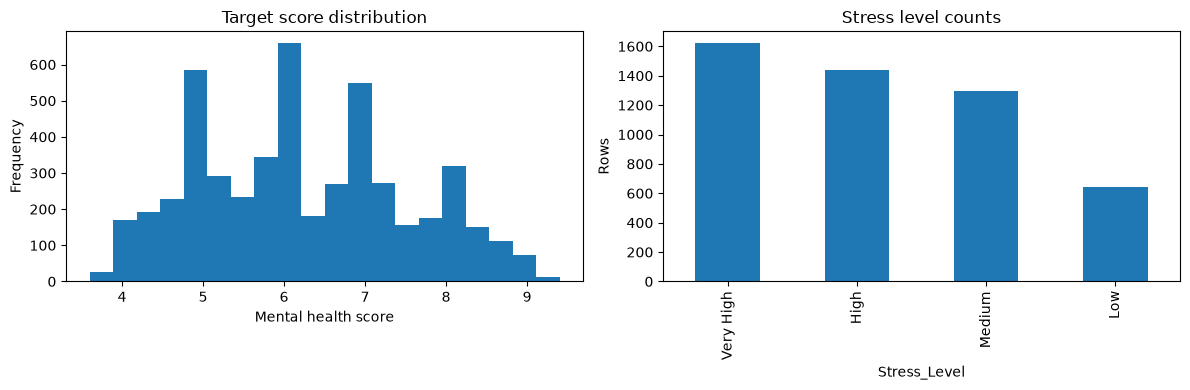

Số giá trị Physical_Activity_Hours âm cần chặn về 0: 10


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data["Mental_Health_Score"].plot(kind="hist", bins=20, ax=axes[0], title="Target score distribution")
data["Stress_Level"].value_counts().plot(kind="bar", ax=axes[1], title="Stress level counts")
axes[0].set_xlabel("Mental health score")
axes[1].set_ylabel("Rows")
plt.tight_layout()
plt.show()

negative_activity = int((data["Physical_Activity_Hours"] < 0).sum())
print(f"Số giá trị Physical_Activity_Hours âm cần chặn về 0: {negative_activity}")

## 2. Tiền xử lý và đánh giá

Mô hình dùng One-Hot Encoding cho dữ liệu phân loại và Random Forest cho hồi quy. Tập kiểm tra 20% được giữ riêng để báo cáo MAE, RMSE và R²; sau đánh giá, pipeline được fit lại bằng toàn bộ dữ liệu để phục vụ API.

In [4]:
X, y, cleaning_report = prepare_dataset(data)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Cleaning report:", cleaning_report)

model, metrics, evaluation, cleaning_report = train_model(data)
print("Holdout metrics:")
for name, value in metrics.items():
    print(f"{name.upper()}: {value:.4f}")

Feature shape: (5000, 12)
Target shape: (5000,)
Cleaning report: {'negative_physical_activity_values_clipped': 10}
Holdout metrics:
MAE: 0.2855
RMSE: 0.3947
R2: 0.9102


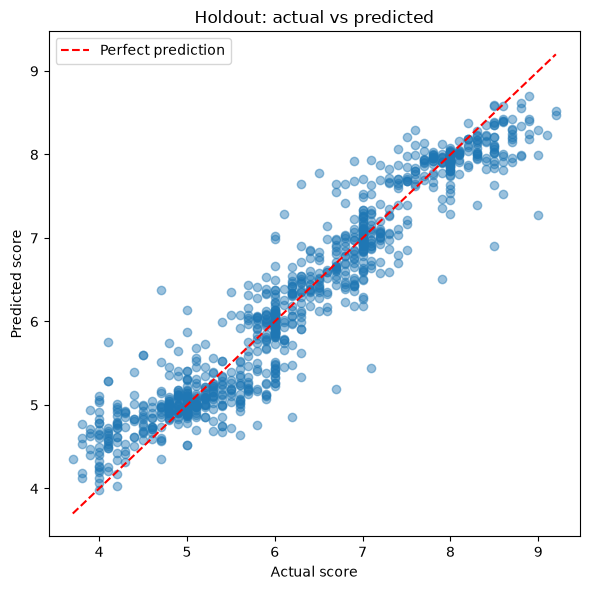

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(evaluation["actual"], evaluation["predicted"], alpha=0.45)
limits = [min(evaluation.min()), max(evaluation.max())]
ax.plot(limits, limits, "--", color="red", label="Perfect prediction")
ax.set(xlabel="Actual score", ylabel="Predicted score", title="Holdout: actual vs predicted")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Lưu model cho API

Chạy cell này để tạo/cập nhật `artifacts/mental_health_model.joblib` và `artifacts/metrics.json`.

In [6]:
metadata = save_artifacts(
    model=model,
    metrics=metrics,
    training_rows=len(data),
    cleaning_report=cleaning_report,
    artifact_path=DEFAULT_ARTIFACT_PATH,
    metrics_path=DEFAULT_METRICS_PATH,
)
metadata

{'model_version': '1.0.0',
 'target_column': 'Mental_Health_Score',
 'feature_columns': ['Age',
  'Gender',
  'Country',
  'Academic_Level',
  'Most_Used_Platform',
  'Purpose_Of_Use',
  'Avg_Daily_Usage_Hours',
  'Daily_Unlocks',
  'Study_Hours',
  'Physical_Activity_Hours',
  'Sleep_Hours_Per_Night',
  'Stress_Level'],
 'metrics': {'mae': 0.285515145879121,
  'rmse': 0.39471013891957935,
  'r2': 0.9101586694387274},
 'training_rows': 5000,
 'cleaning_report': {'negative_physical_activity_values_clipped': 10},
 'trained_at_utc': '2026-11-01T16:17:46.735678+00:00'}